In [2]:
import pandas as pd

df = pd.read_csv("toxic_comments_dataset.csv")

# First 10 and last 8 records
print("First 10 records:")
display(df.head(10))

print("\nLast 8 records:")
display(df.tail(8))

# Shape
print("\nDataset Shape:", df.shape)

# Column names and data types
print("\nColumn Names and Data Types:")
print(df.dtypes)

# Statistical summary of numerical columns
print("\nStatistical Summary:")
display(df.describe())

First 10 records:


,Comment_ID,Comment_Text,Toxicity_Label,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count,Platform,Topic,Moderation_Priority,Language
0,COM000001,The message targets a group unfairly and viola...,Identity_Attack,0,1,0,0,1,0.818,66,10,Community Chat,Sports,High,English
1,COM000002,Thank you for sharing this perspective with th...,Clean,1,0,0,0,0,0.069,58,9,News Comments,Entertainment,High,English
2,COM000003,That response is aggressive and not helpful.,Toxic,0,1,0,0,0,0.622,44,7,Social Media,Politics,Low,English
3,COM000004,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.010,61,9,Social Media,Entertainment,Low,English
4,COM000005,I respectfully disagree but I understand your ...,Clean,1,0,0,0,0,0.140,52,8,Blog,Sports,Low,English
5,COM000006,That response is aggressive and not helpful.,Toxic,0,1,0,0,0,0.729,44,7,Social Media,Technology,Low,English
6,COM000007,I respectfully disagree but I understand your ...,Clean,1,0,0,0,0,0.193,52,8,Blog,Entertainment,Low,English
7,COM000008,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.183,61,9,Forum,Gaming,Low,English
8,COM000009,This article provides useful information and c...,Clean,1,0,0,0,0,0.142,60,8,Social Media,Education,Medium,English
9,COM000010,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.153,61,9,Forum,Entertainment,Low,English



Last 8 records:


,Comment_ID,Comment_Text,Toxicity_Label,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count,Platform,Topic,Moderation_Priority,Language
29992,COM029993,Your message is unnecessarily hostile and offe...,Toxic,0,1,0,0,0,0.520,52,7,Forum,Gaming,Medium,English
29993,COM029994,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.195,61,9,News Comments,Sports,Medium,English
29994,COM029995,Thank you for sharing this perspective with th...,Clean,1,0,0,0,0,0.174,58,9,Community Chat,Gaming,Low,English
29995,COM029996,This article provides useful information and c...,Clean,1,0,0,0,0,0.013,60,8,Community Chat,Sports,Medium,English
29996,COM029997,I respectfully disagree but I understand your ...,Clean,1,0,0,0,0,0.050,52,8,Blog,Politics,Medium,English
29997,COM029998,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.078,61,9,Forum,Sports,Low,English
29998,COM029999,This article provides useful information and c...,Clean,1,0,0,0,0,0.003,60,8,Social Media,Sports,Medium,English
29999,COM030000,I appreciate your explanation and the discussi...,Clean,1,0,0,0,0,0.082,61,9,Community Chat,Education,High,English



Dataset Shape: (30000, 15)

Column Names and Data Types:
Comment_ID                 str
Comment_Text               str
Toxicity_Label             str
Clean                    int64
Toxic                    int64
Severe_Toxic             int64
Threat                   int64
Identity_Attack          int64
Toxicity_Score         float64
Comment_Length           int64
Word_Count               int64
Platform                   str
Topic                      str
Moderation_Priority        str
Language                   str
dtype: object

Statistical Summary:


,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.619300,0.380700,0.060033,0.048633,0.048933,0.324542,56.357633,8.340633
std,0.485567,0.485567,0.237553,0.215104,0.215732,0.302914,6.962596,0.972094
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,39.000000,6.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.079000,52.000000,8.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.161000,58.000000,8.000000
75%,1.000000,1.000000,0.000000,0.000000,0.000000,0.624000,61.000000,9.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,0.950000,71.000000,11.000000


Number of duplicate records: 0

Missing values in each column:
Comment_ID             0
Comment_Text           0
Toxicity_Label         0
Clean                  0
Toxic                  0
Severe_Toxic           0
Threat                 0
Identity_Attack        0
Toxicity_Score         0
Comment_Length         0
Word_Count             0
Platform               0
Topic                  0
Moderation_Priority    0
Language               0
dtype: int64
                                        Comment_Text  \
0  the message targets a group unfairly and viola...   
1  thank you for sharing this perspective with th...   
2       that response is aggressive and not helpful.   
3  i appreciate your explanation and the discussi...   
4  i respectfully disagree but i understand your ...   
5       that response is aggressive and not helpful.   
6  i respectfully disagree but i understand your ...   
7  i appreciate your explanation and the discussi...   
8  this article provides useful information a

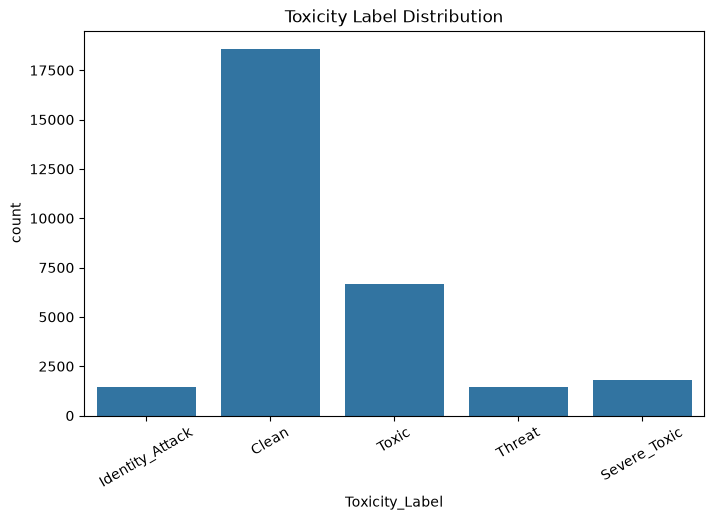

In [3]:
# Convert comments to lowercase
df['Comment_Text'] = df['Comment_Text'].astype(str).str.lower()

# Check duplicates
print("Number of duplicate records:", df.duplicated().sum())

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Drop duplicates and missing values
df.drop_duplicates(inplace=True)
df.dropna(subset=['Comment_Text', 'Toxicity_Label'], inplace=True)

import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['Clean_Comment'] = df['Comment_Text'].apply(clean_text)

print(df[['Comment_Text', 'Clean_Comment']].head(10))

print("\nToxicity Label Distribution:")
print(df['Toxicity_Label'].value_counts())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Toxicity_Label')
plt.title("Toxicity Label Distribution")
plt.xticks(rotation=30)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Encode labels
le = LabelEncoder()
df['Label_Encoded'] = le.fit_transform(df['Toxicity_Label'])

num_classes = df['Label_Encoded'].nunique()
print("Number of classes:", num_classes)
print("Classes:", list(le.classes_))

# Train-test split
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['Clean_Comment'], df['Label_Encoded'], test_size=0.2, random_state=42
)

# Tokenizer - fit only on training text
vocab_size = 10000
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

# Convert text to sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

# Padding
max_len = 100
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

print("Training data shape:", X_train_pad.shape)
print("Testing data shape:", X_test_pad.shape)

Number of classes: 5
Classes: ['Clean', 'Identity_Attack', 'Severe_Toxic', 'Threat', 'Toxic']
Training data shape: (24000, 100)
Testing data shape: (6000, 100)


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical

# One-hot encode labels
y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_test_cat = to_categorical(y_test, num_classes=num_classes)

embedding_dim = 64

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_len),
    LSTM(64, return_sequences=False),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    X_train_pad, y_train_cat,
    epochs=15,
    batch_size=32,
    validation_split=0.2
)

c:\Users\saad\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 58s 71ms/step - accuracy: 0.6124 - loss: 1.1463 - val_accuracy: 0.6119 - val_loss: 1.1159
Epoch 2/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 69s 56ms/step - accuracy: 0.6173 - loss: 1.1134 - val_accuracy: 0.6119 - val_loss: 1.1234
Epoch 3/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 41s 69ms/step - accuracy: 0.6173 - loss: 1.1107 - val_accuracy: 0.6119 - val_loss: 1.1158
Epoch 4/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 35s 59ms/step - accuracy: 0.6173 - loss: 1.1055 - val_accuracy: 0.6119 - val_loss: 1.1155
Epoch 5/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 35s 58ms/step - accuracy: 0.6173 - loss: 1.1037 - val_accuracy: 0.6119 - val_loss: 1.1153
Epoch 6/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 36s 60ms/step - accuracy: 0.6173 - loss: 1.1025 - val_accuracy: 0.6119 - val_loss: 1.1147
Epoch 7/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 38s 64ms/step - accuracy: 0.6173 - loss: 1.1019 - val_accuracy: 0.6119 - val_loss: 1.1167
Epoch 8/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 37s 62ms/step - accuracy: 0.6173 - loss: 1.1020 - 

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate on test data
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test_cat)
print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

# Predictions
y_pred_probs = model.predict(X_test_pad)
y_pred = np.argmax(y_pred_probs, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_.astype(str)))

# Accuracy and Loss curves
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Test model on new comments
new_comments = [
    "You are such a wonderful and kind person",
    "I will hurt you if you say that again",
    "This is the best day of my life"
]

new_comments_clean = [clean_text(c) for c in new_comments]
new_seq = tokenizer.texts_to_sequences(new_comments_clean)
new_pad = pad_sequences(new_seq, maxlen=max_len, padding='post', truncating='post')

predictions = model.predict(new_pad)
predicted_classes = np.argmax(predictions, axis=1)
predicted_labels = le.inverse_transform(predicted_classes)

for comment, label in zip(new_comments, predicted_labels):
    print(f"Comment: {comment} --> Predicted Toxicity: {label}")

188/188 ━━━━━━━━━━━━━━━━━━━━ 13s 24ms/step - accuracy: 0.6315 - loss: 1.0737
Test Accuracy: 0.6315000057220459
Test Loss: 1.0736967325210571
